Загрузим датасет

In [1]:
import os
import torch
import torchvision
import torch.nn as nn
from torchvision import datasets
from torchvision.transforms import v2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используем устройство {device}, Версия pytorch {torch.__version__}')
from torch.utils.data import DataLoader

Используем устройство cuda, Версия pytorch 2.14.1+cu130


Настроим считывание датасета и объявим dataloader. На данном этапе работаем с бинарной классификацией кошка/собака

In [32]:
def convert_classes(main_label):
    if main_label < 12:
        return 0 
    else:
        return 1

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    # v2.Normalize(
    # mean=[0.485, 0.456, 0.406],
    # std=[0.229, 0.224, 0.225],),
    v2.Resize((64, 64)),
])

train_dataset = datasets.ImageFolder(root = '/workspace/neural_networks/datasets/petfaces/train', transform=transform, target_transform=convert_classes)
test_dataset = datasets.ImageFolder(root = '/workspace/neural_networks/datasets/petfaces/test', transform=transform, target_transform=convert_classes)

batch_size = 32

train_loader = DataLoader(train_dataset, batch_size, shuffle=True, pin_memory=(device.type == 'cuda'))
test_loader = DataLoader(test_dataset, batch_size, shuffle=False)


In [34]:
for X, y in train_loader:
    print(f"Размер батча X [N, C, H, W]: {X.shape}")
    print(f"Размер меток y: {y.shape} | Тип: {y.dtype}")
    break

Размер батча X [N, C, H, W]: torch.Size([32, 3, 64, 64])
Размер меток y: torch.Size([32]) | Тип: torch.int64


Индексы классов будут маппиться в 0 или 1 по своему значению (у кошек < 12)

In [33]:
print(train_dataset.class_to_idx)

{'cat_Abyssinian': 0, 'cat_Bengal': 1, 'cat_Birman': 2, 'cat_Bombay': 3, 'cat_British': 4, 'cat_Egyptian': 5, 'cat_Maine': 6, 'cat_Persian': 7, 'cat_Ragdoll': 8, 'cat_Russian': 9, 'cat_Siamese': 10, 'cat_Sphynx': 11, 'dog_american': 12, 'dog_basset': 13, 'dog_beagle': 14, 'dog_boxer': 15, 'dog_chihuahua': 16, 'dog_english': 17, 'dog_german': 18, 'dog_great': 19, 'dog_havanese': 20, 'dog_japanese': 21, 'dog_keeshond': 22, 'dog_leonberger': 23, 'dog_miniature': 24, 'dog_newfoundland': 25, 'dog_pomeranian': 26, 'dog_pug': 27, 'dog_saint': 28, 'dog_samoyed': 29, 'dog_scottish': 30, 'dog_shiba': 31, 'dog_staffordshire': 32, 'dog_wheaten': 33, 'dog_yorkshire': 34}


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].


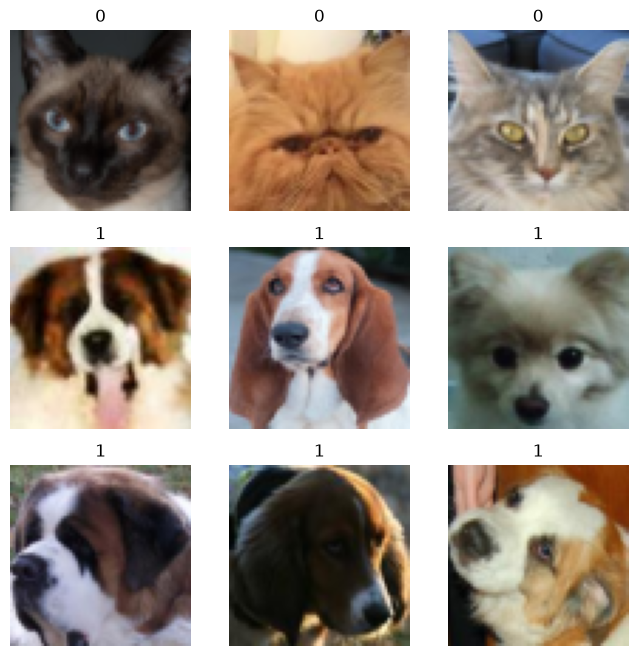

In [24]:
import matplotlib.pyplot as plt
    
# Опишем название классов:
labels_map = ['0','1']
 
# Визуализируем рандомные сэмплы из MNIST:
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_dataset), size=(1,)).item()
    img, label = train_dataset[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    
    plt.imshow(img.permute(1,2,0)) # squeeze() - удаляем все измерения размером 1
plt.show()

Создадим простую полносвязную сеть и попробуем обучить ее

In [25]:
class BinaryMLP(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(3*64*64, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 16),
            nn.ReLU(),
            nn.Linear(16, num_classes),
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)

model = BinaryMLP().to(device)

In [26]:
print(model)

BinaryMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=12288, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=2, bias=True)
  )
)


Функции обучения и валидации

In [2]:
def train_epoch(model, train_loader, loss_criterion, optimizer, device):
    epoch_loss = 0
    model.train()
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        output = model.forward(X)
        loss = loss_criterion(output, y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
    return epoch_loss / (len(train_loader) * batch_size)


def eval(model, test_loader, loss_criterion, device):
    epoch_loss = 0
    correct = 0
    model.eval()
    with torch.no_grad():
        for X, y in test_loader:
            X, y = X.to(device), y.to(device)
            output = model.forward(X)
            loss = loss_criterion(output, y)

            epoch_loss += loss.item()
            correct += (output.argmax(dim=1) == y).sum().item()
    return epoch_loss / len(test_loader) * batch_size, correct / (len(test_loader) * batch_size)

Как видно из лога, сеть действительно обучается, однако, несмотря на большой learning rate (что видно по большому разбросу динамики accuracy), сеть обучается плохо и нестабильно
Теоретически, при правильно подобранном lr, можно было бы получить точность до 80%

In [37]:
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)
epochs = 30

for epoch in range(epochs):
    train_loss = train_epoch(model, train_loader, loss, optimizer, device)
    test_loss, acc = eval(model, test_loader, loss, device)

    print(f'Эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

Эпоха 0: train loss = 0.01920705060991976, test_loss = 19.74691595349993, accuracy = 0.6339285714285714
Эпоха 1: train loss = 0.01870046381229236, test_loss = 19.556358882359095, accuracy = 0.6547619047619048
Эпоха 2: train loss = 0.01819213112977184, test_loss = 18.81539689926874, accuracy = 0.6666666666666666
Эпоха 3: train loss = 0.017601115456609813, test_loss = 18.03026076725551, accuracy = 0.6800595238095238
Эпоха 4: train loss = 0.016963121239785797, test_loss = 17.622337840852282, accuracy = 0.6845238095238095
Эпоха 5: train loss = 0.01659049593878013, test_loss = 17.8432833807809, accuracy = 0.6741071428571429
Эпоха 6: train loss = 0.016031658920792887, test_loss = 16.719796180725098, accuracy = 0.7008928571428571
Эпоха 7: train loss = 0.015810138821877814, test_loss = 16.231292860848562, accuracy = 0.7247023809523809
Эпоха 8: train loss = 0.015274154758195818, test_loss = 16.31006055786496, accuracy = 0.7008928571428571
Эпоха 9: train loss = 0.014648479524493954, test_loss = 

Попробуем использовать более продвинутый алгоритм оптимизации - AdamW

In [39]:
model2 = BinaryMLP().to(device)
loss2 = nn.CrossEntropyLoss()
optimizer2 = torch.optim.AdamW(model2.parameters(), lr=1e-3)
epochs = 30



Видно, что динамика обучения стала стабильнее. Однако, полносвязные сети - не лучший выбор для классификации изображений

In [40]:
for epoch in range(epochs):
    train_loss = train_epoch(model2, train_loader, loss2, optimizer2, device)
    test_loss, acc = eval(model2, test_loader, loss2, device)

    print(f'Эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

Эпоха 0: train loss = 0.020956956241049884, test_loss = 20.18431300208682, accuracy = 0.6294642857142857
Эпоха 1: train loss = 0.019301492410401504, test_loss = 19.54642241341727, accuracy = 0.6592261904761905
Эпоха 2: train loss = 0.017968372315352345, test_loss = 21.386313574654714, accuracy = 0.5907738095238095
Эпоха 3: train loss = 0.017322595783129887, test_loss = 16.732937971750896, accuracy = 0.7053571428571429
Эпоха 4: train loss = 0.015126457800053887, test_loss = 16.47055573690505, accuracy = 0.7008928571428571
Эпоха 5: train loss = 0.013568239550991559, test_loss = 16.667994544619607, accuracy = 0.7023809523809523
Эпоха 6: train loss = 0.013581753984369614, test_loss = 16.562738191513787, accuracy = 0.7142857142857143
Эпоха 7: train loss = 0.013680625706911087, test_loss = 15.111743927001953, accuracy = 0.7410714285714286
Эпоха 8: train loss = 0.012432554058362673, test_loss = 18.199806031726656, accuracy = 0.6488095238095238
Эпоха 9: train loss = 0.012309862674432404, test_

Создадим сеть с архитектурой базовой сверточной сети по аналогии с LeNet, с дополнительными современными улучшениями

In [3]:
class BetterNet(nn.Module):
    def __init__(self, num_classes = 2, input_channels=1, batch_norm=True):
        super().__init__()

        def conv_block(in_channels, out_channels):
            layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)]
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.append(nn.ReLU(inplace=True))
            return layers

        self.feature_extractor = nn.Sequential(
            *conv_block(input_channels, 32),
            nn.MaxPool2d(kernel_size=2),

            *conv_block(32, 64),
            nn.MaxPool2d(kernel_size=2),

            nn.AdaptiveAvgPool2d((4, 4))

        )

        self.classifier_head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.1),
            nn.Linear(64 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.feature_extractor(x)
        x = self.classifier_head(x)
        return x


        

In [4]:
model3 = BetterNet(input_channels=3).to(device)
loss3 = nn.CrossEntropyLoss()
optimizer3 = torch.optim.AdamW(model3.parameters(), lr=1e-3)
epochs = 30



Как видим, обучение сверточной сети идет гораздо стабильнее, и приносит лучшие результаты.

In [52]:
for epoch in range(epochs):
    train_loss = train_epoch(model3, train_loader, loss3, optimizer3, device)
    test_loss, acc = eval(model3, test_loader, loss3, device)

    print(f'Эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

Эпоха 0: train loss = 0.016857436559174533, test_loss = 13.211206526983352, accuracy = 0.8020833333333334
Эпоха 1: train loss = 0.009559517424484645, test_loss = 9.09489553315299, accuracy = 0.8541666666666666
Эпоха 2: train loss = 0.008841099145672755, test_loss = 12.245879309517997, accuracy = 0.8139880952380952
Эпоха 3: train loss = 0.007091228375901227, test_loss = 8.439685283672242, accuracy = 0.8541666666666666
Эпоха 4: train loss = 0.006079114757961145, test_loss = 7.761895506154923, accuracy = 0.8690476190476191
Эпоха 5: train loss = 0.0051646744329367335, test_loss = 7.413913746674855, accuracy = 0.8660714285714286
Эпоха 6: train loss = 0.005659083535400346, test_loss = 9.663798833177204, accuracy = 0.8348214285714286
Эпоха 7: train loss = 0.00494493060403239, test_loss = 9.08699233084917, accuracy = 0.8511904761904762
Эпоха 8: train loss = 0.004232404459653031, test_loss = 6.724571152811959, accuracy = 0.8839285714285714
Эпоха 9: train loss = 0.0037362313249351795, test_loss 

Попробуем обучить ту же сеть, но для задачи многоклассовой классификации

In [5]:

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    # v2.Normalize(
    # mean=[0.485, 0.456, 0.406],
    # std=[0.229, 0.224, 0.225],),
    v2.Resize((64, 64)),
])

train_dataset2 = datasets.ImageFolder(root = '/workspace/neural_networks/datasets/petfaces/train', transform=transform)
test_dataset2 = datasets.ImageFolder(root = '/workspace/neural_networks/datasets/petfaces/test', transform=transform)

batch_size = 32

train_loader2 = DataLoader(train_dataset2, batch_size, shuffle=True, pin_memory=(device.type == 'cuda'))
test_loader2 = DataLoader(test_dataset2, batch_size, shuffle=False)


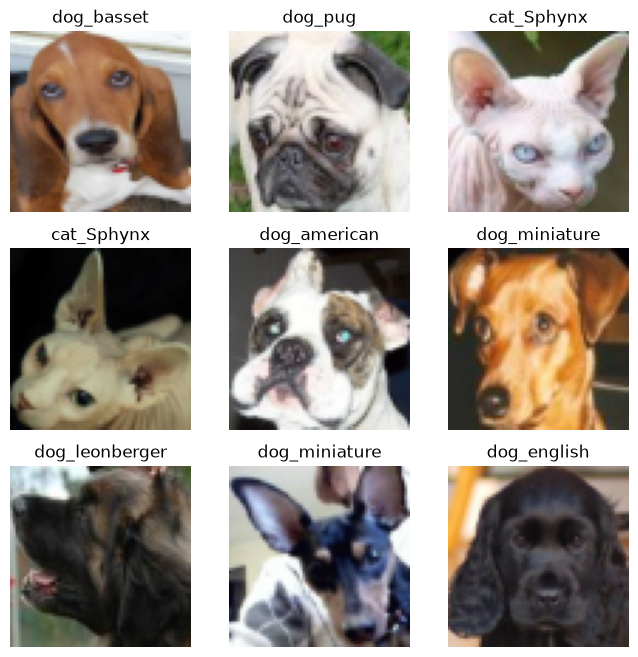

In [6]:
import matplotlib.pyplot as plt
    
# Опишем название классов:
labels_map = train_dataset2.classes

 
# Визуализируем рандомные сэмплы из MNIST:
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_dataset2), size=(1,)).item()
    img, label = train_dataset2[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    
    plt.imshow(img.permute(1,2,0)) # squeeze() - удаляем все измерения размером 1
plt.show()

In [7]:
model4 = BetterNet(input_channels=3, num_classes=35).to(device)
loss4 = nn.CrossEntropyLoss()
optimizer4 = torch.optim.AdamW(model4.parameters(), lr=1e-3)
epochs = 30

In [9]:
for epoch in range(epochs):
    train_loss = train_epoch(model4, train_loader2, loss4, optimizer4, device)
    test_loss, acc = eval(model4, test_loader2, loss4, device)

    print(f'Эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

Эпоха 0: train loss = 0.008607691700029889, test_loss = 50.865352676028294, accuracy = 0.5907738095238095
Эпоха 1: train loss = 0.008535932900418562, test_loss = 49.93204289390927, accuracy = 0.5892857142857143
Эпоха 2: train loss = 0.008424833928591308, test_loss = 51.338992754618324, accuracy = 0.5595238095238095
Эпоха 3: train loss = 0.007571463382595943, test_loss = 56.22887320745559, accuracy = 0.5744047619047619
Эпоха 4: train loss = 0.007925775594848358, test_loss = 53.834499177478605, accuracy = 0.5744047619047619
Эпоха 5: train loss = 0.006932560843128113, test_loss = 50.668998536609465, accuracy = 0.5997023809523809
Эпоха 6: train loss = 0.007169428945484536, test_loss = 50.485091243471416, accuracy = 0.59375
Эпоха 7: train loss = 0.006863925674999201, test_loss = 52.31852231706892, accuracy = 0.5773809523809523
Эпоха 8: train loss = 0.007054911210650095, test_loss = 58.862711066291446, accuracy = 0.5327380952380952
Эпоха 9: train loss = 0.006961064482176745, test_loss = 53.8

In [30]:
correct3 = correct5 = total = 0
model4.eval()

with torch.no_grad():
    for X, y in test_loader2:
        y = y.to(device)
        top5 = model4(X.to(device)).topk(5, dim=1).indices
        matches = top5 == y[:, None]

        correct3 += matches[:, :3].any(dim=1).sum().item()
        correct5 += matches.any(dim=1).sum().item()
        total += y.size(0)

print(f"Top-3 accuracy: {correct3 / total:.2%}")
print(f"Top-5 accuracy: {correct5 / total:.2%}")

Top-3 accuracy: 83.23%
Top-5 accuracy: 89.60%


Попробуем оптимизировать архитектуру:

In [14]:
class BetterNetV2(nn.Module):
    def __init__(self, num_classes = 35, input_channels=3, batch_norm=True):
        super().__init__()

        def conv_block(in_channels, out_channels):
            layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)]
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.append(nn.ReLU(inplace=True))
            return layers

        self.feature_extractor = nn.Sequential(
            *conv_block(input_channels, 32),
            nn.MaxPool2d(kernel_size=2),

            *conv_block(32, 64),
            nn.MaxPool2d(kernel_size=2),

            *conv_block(64, 128),
            nn.MaxPool2d(kernel_size=2),

            nn.AdaptiveAvgPool2d((4, 4))

        )

        self.classifier_head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.2),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.feature_extractor(x)
        x = self.classifier_head(x)
        return x


        

Добавим аугментации

In [11]:

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05)),
    v2.ColorJitter(brightness=0.1, contrast=0.1),
    v2.Resize((128, 128)),
])

train_dataset3 = datasets.ImageFolder(root = '/workspace/neural_networks/datasets/petfaces/train', transform=transform)
test_dataset3 = datasets.ImageFolder(root = '/workspace/neural_networks/datasets/petfaces/test', transform=transform)

batch_size = 32

train_loader3 = DataLoader(train_dataset3, batch_size, shuffle=True, pin_memory=(device.type == 'cuda'))
test_loader3 = DataLoader(test_dataset3, batch_size, shuffle=False)


In [15]:
model5 = BetterNetV2(input_channels=3, num_classes=35).to(device)
loss5 = nn.CrossEntropyLoss()
optimizer5 = torch.optim.AdamW(model5.parameters(), lr=1e-3)
epochs = 30

In [17]:
for epoch in range(epochs):
    train_loss = train_epoch(model5, train_loader3, loss5, optimizer5, device)
    test_loss, acc = eval(model5, test_loader3, loss5, device)

    print(f'Эпоха {epoch}: train loss = {train_loss}, test_loss = {test_loss}, accuracy = {acc}')

Эпоха 0: train loss = 0.04501351806116693, test_loss = 41.32607841491699, accuracy = 0.5505952380952381
Эпоха 1: train loss = 0.04466407697785784, test_loss = 43.12301299685524, accuracy = 0.5654761904761905
Эпоха 2: train loss = 0.044421149946657225, test_loss = 40.68956198011126, accuracy = 0.5818452380952381
Эпоха 3: train loss = 0.04444367944458385, test_loss = 38.44279189336868, accuracy = 0.5952380952380952
Эпоха 4: train loss = 0.043627120876385844, test_loss = 43.3198580514817, accuracy = 0.5252976190476191
Эпоха 5: train loss = 0.04191661665193093, test_loss = 52.528230485462004, accuracy = 0.4732142857142857
Эпоха 6: train loss = 0.043648217563275936, test_loss = 39.775212151663645, accuracy = 0.5982142857142857
Эпоха 7: train loss = 0.043597357577563806, test_loss = 41.21935290382022, accuracy = 0.5788690476190477
Эпоха 8: train loss = 0.042926318276627566, test_loss = 41.0489620027088, accuracy = 0.5997023809523809
Эпоха 9: train loss = 0.04168235439301273, test_loss = 45.9

К сожалению, измененный пайплайн не дал значительных улучшений качества модели 

In [29]:
correct3 = correct5 = total = 0
model5.eval()

with torch.no_grad():
    for X, y in test_loader3:
        y = y.to(device)
        top5 = model5(X.to(device)).topk(5, dim=1).indices
        matches = top5 == y[:, None]

        correct3 += matches[:, :3].any(dim=1).sum().item()
        correct5 += matches.any(dim=1).sum().item()
        total += y.size(0)

print(f"Top-3 accuracy: {correct3 / total:.2%}")
print(f"Top-5 accuracy: {correct5 / total:.2%}")

Top-3 accuracy: 86.80%
Top-5 accuracy: 92.08%


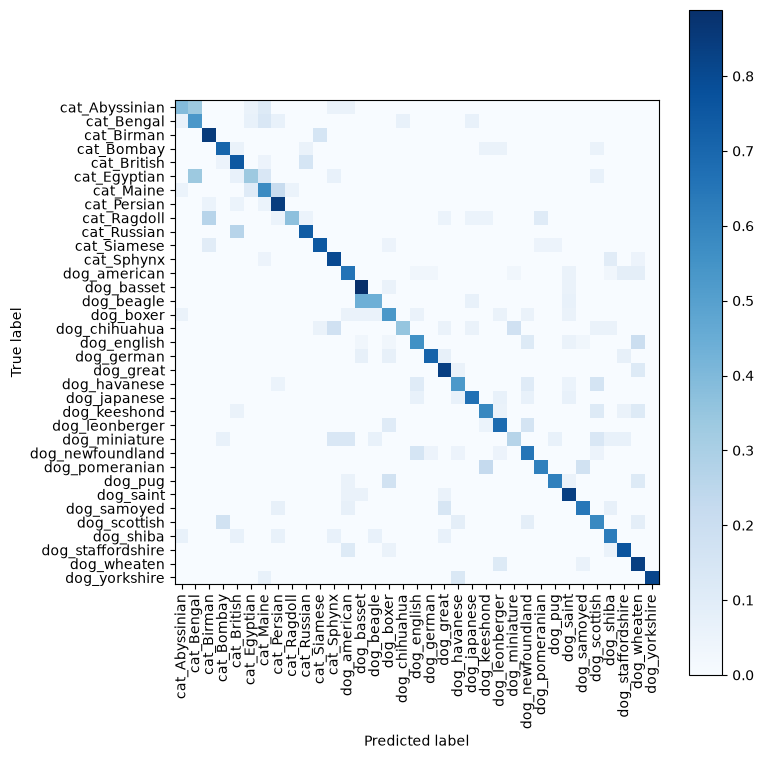

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

y_true, y_pred = [], []
model5.eval()

with torch.no_grad():
    for X, y in test_loader3:
        y_true.extend(y.tolist())
        y_pred.extend(model5(X.to(device)).argmax(1).cpu().tolist())

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=train_dataset3.classes,
    labels=range(len(train_dataset3.classes)),
    normalize="true", include_values=False,
    xticks_rotation=90, cmap="Blues", ax=ax,
)
plt.tight_layout()
plt.show()

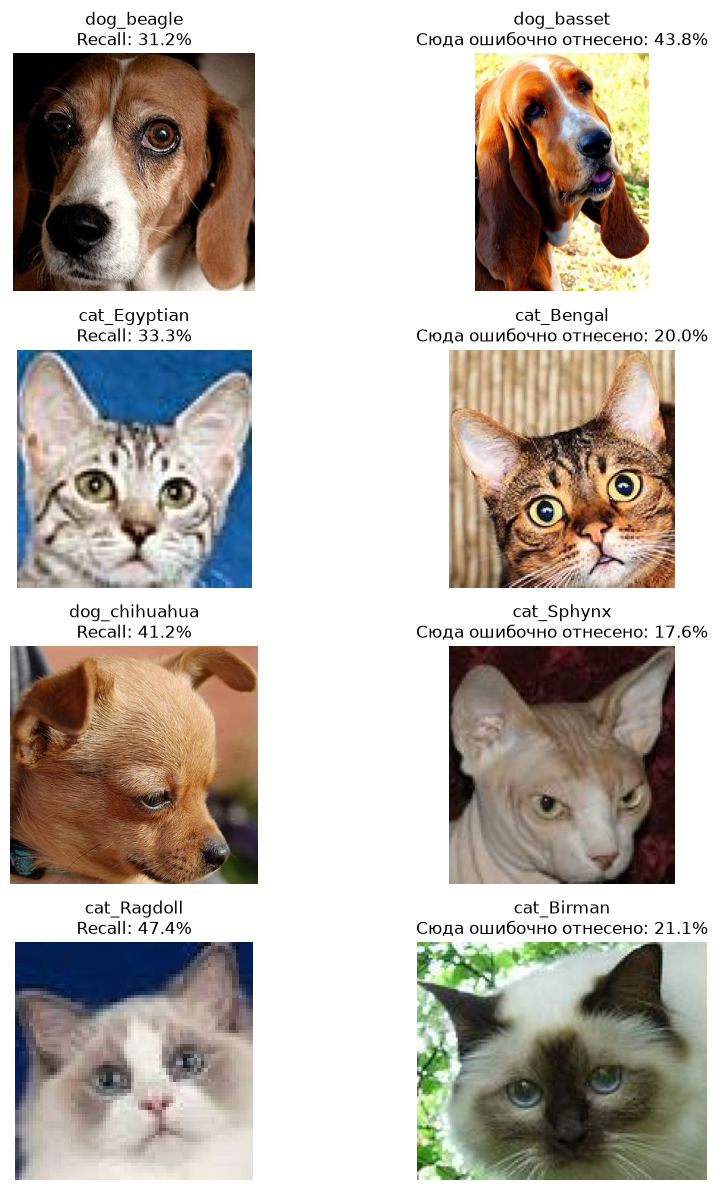

In [26]:
import numpy as np
from sklearn.metrics import confusion_matrix

classes = train_dataset2.classes
targets = np.array(test_dataset2.targets)

cm = confusion_matrix(
    y_true, y_pred, labels=range(len(classes)), normalize="true"
)
recall = cm.diagonal().copy()
np.fill_diagonal(cm, 0)  # Оставляем только ошибки

candidates = np.flatnonzero(cm.max(axis=1) > 0)
worst = candidates[np.argsort(recall[candidates])[:4]]

fig, axes = plt.subplots(4, 2, figsize=(10, 12))
for ax in axes.flat:
    ax.axis("off")

for row, cls in enumerate(worst):
    confused = cm[cls].argmax()
    for col, label in enumerate([cls, confused]):
        idx = np.flatnonzero(targets == label)[0]
        axes[row, col].imshow(plt.imread(test_dataset2.samples[idx][0]))
        axes[row, col].set_title(classes[label])

    axes[row, 0].set_title(f"{classes[cls]}\nRecall: {recall[cls]:.1%}")
    axes[row, 1].set_title(
        f"{classes[confused]}\nСюда ошибочно отнесено: {cm[cls, confused]:.1%}"
    )

plt.tight_layout()
plt.show()

Из сравнения видно, что сеть путает визуально похожие классы